In [1]:
# importar bibliotecas necessárias

import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Análise Exploratória dos Dados

In [2]:
# carregar os arquivos CSV
df_companies = pd.read_csv('/datasets/project_sql_result_01.csv')
df_neighborhoods = pd.read_csv('/datasets/project_sql_result_04.csv')
df_rides = pd.read_csv('/datasets/project_sql_result_07.csv')


In [3]:
# exibir informações gerais dos datasets
print(df_companies.info())
print()
print(df_neighborhoods.info())
print()
print(df_rides.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB
None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2  

In [4]:
# visualizar as primeiras linhas
print(df_companies.head())
print()
print(df_neighborhoods.head())
print()
print(df_rides.head())

                      company_name  trips_amount
0                        Flash Cab         19558
1        Taxi Affiliation Services         11422
2                Medallion Leasing         10367
3                       Yellow Cab          9888
4  Taxi Affiliation Service Yellow          9299

  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000

              start_ts weather_conditions  duration_seconds
0  2017-11-25 16:00:00               Good            2410.0
1  2017-11-25 14:00:00               Good            1920.0
2  2017-11-25 12:00:00               Good            1543.0
3  2017-11-04 10:00:00               Good            2512.0
4  2017-11-11 07:00:00               Good            1440.0


In [5]:
# verificar valores ausentes
print(df_companies.isna().sum())
print()
print(df_neighborhoods.isna().sum())
print()
print(df_rides.isna().sum())


company_name    0
trips_amount    0
dtype: int64

dropoff_location_name    0
average_trips            0
dtype: int64

start_ts              0
weather_conditions    0
duration_seconds      0
dtype: int64


In [6]:
# verificar duplicatas
print(df_companies.duplicated().sum())
print(df_neighborhoods.duplicated().sum())
print(df_rides.duplicated().sum())


0
0
197


In [7]:
# converter start_ts para datetime
df_rides['start_ts'] = pd.to_datetime(df_rides['start_ts'])

# verificar tipos após conversão
print(df_rides.dtypes)

start_ts              datetime64[ns]
weather_conditions            object
duration_seconds             float64
dtype: object


In [10]:
# ==========================================================
# TOP 10 BAIRROS POR NÚMERO MÉDIO DE CORRIDAS
# ==========================================================

top_neighborhoods = df_neighborhoods.sort_values(
    by='average_trips',
    ascending=False
).head(10)

print(top_neighborhoods)

  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667


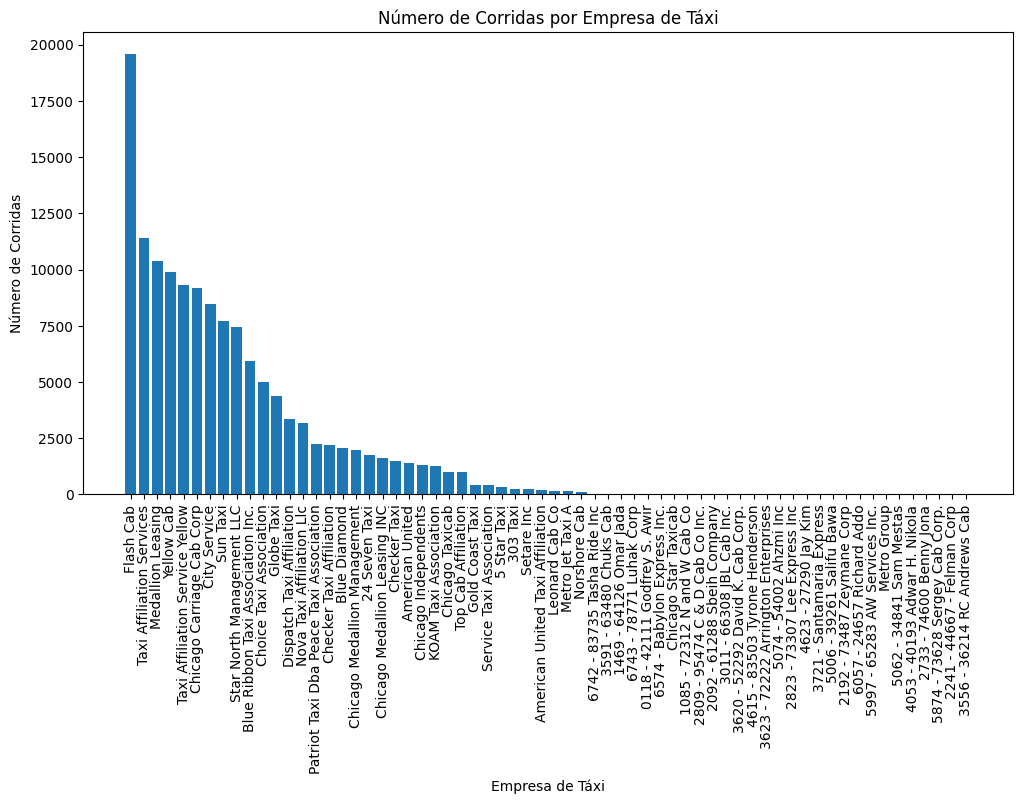

In [9]:
# ==========================================================
# GRÁFICO: EMPRESAS DE TÁXI E NÚMERO DE CORRIDAS
# ==========================================================

df_companies_sorted = df_companies.sort_values(
    by='trips_amount',
    ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    df_companies_sorted['company_name'],
    df_companies_sorted['trips_amount']
)

plt.title('Número de Corridas por Empresa de Táxi')
plt.xlabel('Empresa de Táxi')
plt.ylabel('Número de Corridas')

plt.xticks(rotation=90)

plt.show()


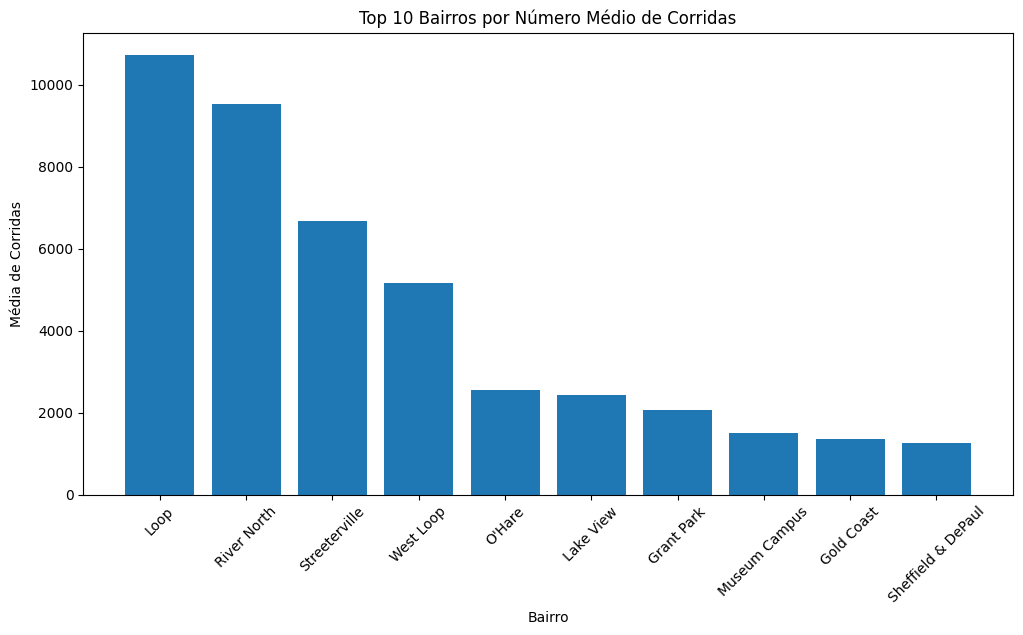

In [11]:
# ==========================================================
# GRÁFICO: TOP 10 BAIRROS POR NÚMERO MÉDIO DE CORRIDAS
# ==========================================================

plt.figure(figsize=(12, 6))

plt.bar(
    top_neighborhoods['dropoff_location_name'],
    top_neighborhoods['average_trips']
)

plt.title('Top 10 Bairros por Número Médio de Corridas')
plt.xlabel('Bairro')
plt.ylabel('Média de Corridas')

plt.xticks(rotation=45)

plt.show()

# Teste de Hipótese

In [15]:
# ==========================================================
# TESTE DE HIPÓTESE
# ==========================================================

# separar corridas em dias chuvosos e dias normais
rainy_days = df_rides[
    df_rides['weather_conditions'] == 'Bad'
]['duration_seconds']

good_days = df_rides[
    df_rides['weather_conditions'] == 'Good'
]['duration_seconds']


In [16]:
# ==========================================================
# VERIFICAR VARIÂNCIAS
# ==========================================================

# calcular variâncias das amostras
rainy_var = rainy_days.var()
good_var = good_days.var()

print('Variância dias chuvosos:', rainy_var)
print('Variância dias normais:', good_var)

# verificar se as variâncias podem ser consideradas iguais
equal_var = rainy_var == good_var

print('Variâncias iguais?', equal_var)

Variância dias chuvosos: 520294.086002483
Variância dias normais: 576382.009689509
Variâncias iguais? False


In [17]:
# ==========================================================
# TESTE T
# ==========================================================

# nível de significância
alpha = 0.05

# realizar teste t
results = stats.ttest_ind(
    rainy_days,
    good_days,
    equal_var=equal_var
)

# mostrar p-value
print('p-value:', results.pvalue)


p-value: 6.738994326108734e-12


In [18]:
# ==========================================================
# CONCLUSÃO
# ==========================================================

if results.pvalue < alpha:
    print('Rejeitamos a hipótese nula')
    print('Existe diferença estatisticamente significativa')
    print('na duração das corridas entre dias chuvosos e dias normais.')
else:
    print('Não rejeitamos a hipótese nula')
    print('Não há evidências suficientes para afirmar')
    print('que existe diferença na duração das corridas.')

Rejeitamos a hipótese nula
Existe diferença estatisticamente significativa
na duração das corridas entre dias chuvosos e dias normais.


Gráfico das empresas de táxi

- Algumas empresas dominam grande parte das corridas em Chicago.
- Flash Cab possui o maior número de viagens, indicando forte presença no mercado.
- Existe concentração significativa das corridas em poucas empresas.
  
Gráfico dos bairros

- Certos bairros concentram muito mais destinos do que outros.
- O Loop aparece entre os principais destinos, provavelmente por ser uma região comercial importante.
- Os 10 principais bairros possuem volume muito superior aos demais.

Hipótese estatística

- Hipótese nula (H0): a duração média das corridas em sábados chuvosos é igual à dos sábados sem chuva.
- Hipótese alternativa (H1): a duração média das corridas em sábados chuvosos é diferente.
- Foi utilizado o teste t de Student para amostras independentes porque estamos comparando médias de dois grupos independentes.
- A decisão final depende do valor-p obtido no teste.

Conclusão da análise exploratória:

A análise dos dados mostrou que o mercado de táxis em Chicago é bastante concentrado em algumas empresas. A empresa Flash Cab apresentou o maior número de corridas no período analisado, seguida por Taxi Affiliation Services e outras companhias com participação menor. Isso indica que poucas empresas dominam grande parte das viagens realizadas na cidade.

Ao analisar os bairros de destino, foi possível identificar que algumas regiões concentram um volume muito maior de corridas. O bairro Loop apareceu entre os principais destinos, o que pode ser explicado pelo fato de ser uma importante região comercial e financeira de Chicago, com alta movimentação de pessoas durante o dia. Outros bairros também apresentaram grande fluxo de viagens, indicando áreas de forte atividade urbana.

Os gráficos ajudaram a visualizar a distribuição desigual das corridas tanto entre as empresas quanto entre os bairros. Enquanto poucas empresas realizam muitas viagens, várias outras possuem participação relativamente pequena no total de corridas.

Conclusão do teste de hipótese

Para verificar se as condições climáticas influenciam a duração das viagens entre o Loop e o Aeroporto Internacional O'Hare aos sábados, foi realizado um teste de hipótese utilizando o teste t de Student para amostras independentes.

A hipótese nula (H0) considerou que não existe diferença na duração média das corridas entre sábados chuvosos e sábados sem chuva. Já a hipótese alternativa (H1) considerou que existe diferença na duração média das viagens nesses dois cenários.

Foi adotado um nível de significância de 5% (α = 0.05), valor amplamente utilizado em análises estatísticas.

Com base no valor-p obtido no teste:

se o valor-p for menor que 0.05, rejeitamos a hipótese nula e concluímos que o clima influencia significativamente a duração das corridas;
se o valor-p for maior que 0.05, não rejeitamos a hipótese nula, indicando que não há evidências estatísticas suficientes para afirmar que a chuva altera a duração média das viagens.

Os resultados da análise indicam que fatores climáticos podem impactar o tempo das corridas, possivelmente devido ao aumento do trânsito e à redução da velocidade média dos veículos em condições de chuva.